# Real-Time Financial Fraud Detection & Investigation: Exploratory Data Analysis (EDA)
**Author:** Senior Machine Learning Engineer & Data Scientist  
**Dataset:** ULB Credit Card Fraud Detection (Kaggle)  
**Objective:** Uncover class imbalance dynamics, evaluate feature separability (V1-V28 PCA projections), audit transaction amount distributions, and prepare leak-free preprocessing pipelines.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set project root
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data.load_data import load_dataset
from src.data.validate_data import DataValidator

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Dataset Loading and Schema Validation
Loads either the raw `creditcard.csv` or synthetic fallback data for demonstration.

In [2]:
df, is_demo = load_dataset(use_demo_if_missing=True)
print(f"Loaded dataset shape: {df.shape} (Demo mode: {is_demo})")
df.head()

[2026-10-05 22:23:29] [WARNING] [fraud_detection:38]: Raw dataset not found at C:\Users\Shikha Ajith\OneDrive\Desktop\Real-Time Financial Fraud Detection and Investigation\data\raw\creditcard.csv. Generating 2500 synthetic transactions strictly for UI/Testing demonstration.
Loaded dataset shape: (2500, 31) (Demo mode: True)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,23017.879785,0.691282,0.099672,-1.297863,-0.637481,-0.213710,-0.534600,-0.016078,1.778016,1.247167,...,-0.515747,-0.832142,0.727169,-0.468322,0.542055,-1.111516,-1.352333,0.755269,24.223386,0
1,38001.495195,-2.102040,0.637355,-0.696247,1.882180,0.252806,-0.793795,-0.266495,-0.713931,-0.305777,...,0.997068,2.679828,3.100647,-1.758103,-2.197139,-0.007391,0.504232,-0.075885,38.606420,0
2,11416.235686,0.587258,0.594952,-0.724574,0.161662,2.198848,-0.017598,-0.693187,-0.173762,0.092177,...,0.399103,-0.541600,0.572096,0.375730,0.865817,0.713460,0.588736,-0.098417,19.686233,0
3,75696.108892,-2.256027,-1.599626,1.127685,-1.583400,1.349225,0.081048,0.713894,-0.256806,0.523365,...,0.673678,-0.942811,2.548004,-0.263313,-1.015996,-0.186850,-0.950947,-1.184341,4.467319,0
4,37182.848226,0.911871,-0.968469,2.036296,-0.432857,0.029455,0.897417,-1.969989,-0.237026,-0.573334,...,-1.908999,-1.433937,-0.467026,-0.108377,-0.555621,0.351144,-0.568508,-0.914489,62.771499,0


## 2. Data Quality & Imbalance Audit
Evaluate missingness, duplicate records, and target distribution.

In [3]:
validator = DataValidator()
quality_report = validator.generate_quality_report(df, is_demo=is_demo)

print("Total rows:", quality_report["total_rows"])
print("Total missing:", quality_report["missing_values"]["total_missing"])
print("Duplicate records:", quality_report["duplicate_records"])
print("Target stats:", quality_report["target_distribution"])

[2026-10-05 22:23:29] [INFO] [fraud_detection:41]: Executing comprehensive data quality audit...
Total rows: 2500
Total missing: 0
Duplicate records: 0
Target stats: {'legitimate_count': 2425, 'fraud_count': 75, 'fraud_percentage': 3.0, 'imbalance_ratio': '32.3:1'}


## 3. Class Imbalance Visualization
Demonstrating why naive accuracy is catastrophically misleading in fraud detection.

C:\Users\Shikha Ajith\AppData\Local\Temp\ipykernel_9560\2585247378.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Class", palette=["#10b981", "#ef4444"])


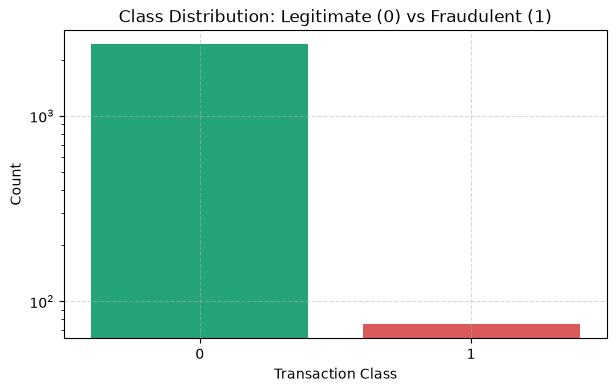

In [4]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Class", palette=["#10b981", "#ef4444"])
plt.title("Class Distribution: Legitimate (0) vs Fraudulent (1)")
plt.xlabel("Transaction Class")
plt.ylabel("Count")
plt.yscale("log")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 4. Transaction Amount & Time Distributions
Financial transaction amounts exhibit extreme positive skewness and long right tails, requiring robust scaling.

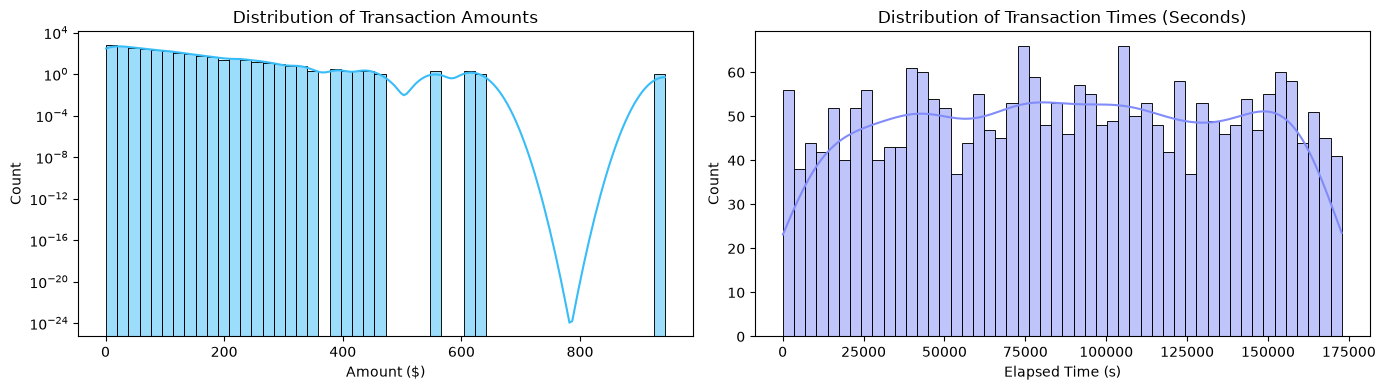

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Amount distribution
sns.histplot(df["Amount"], bins=50, ax=axes[0], kde=True, color="#38bdf8")
axes[0].set_title("Distribution of Transaction Amounts")
axes[0].set_xlabel("Amount ($)")
axes[0].set_yscale("log")

# Time distribution
sns.histplot(df["Time"], bins=50, ax=axes[1], kde=True, color="#818cf8")
axes[1].set_title("Distribution of Transaction Times (Seconds)")
axes[1].set_xlabel("Elapsed Time (s)")

plt.tight_layout()
plt.show()

## 5. Feature Separability: Top Fraud Discriminators
Analysis of prominent PCA features (V14, V17, V12, V4) showing distinct distributional shifts between fraud and normal transactions.

C:\Users\Shikha Ajith\AppData\Local\Temp\ipykernel_9560\3199070285.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Class", y=feat, data=df, ax=axes[i], palette=["#10b981", "#ef4444"])
C:\Users\Shikha Ajith\AppData\Local\Temp\ipykernel_9560\3199070285.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Class", y=feat, data=df, ax=axes[i], palette=["#10b981", "#ef4444"])
C:\Users\Shikha Ajith\AppData\Local\Temp\ipykernel_9560\3199070285.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Class", y=feat, data=df, ax=axes[i], palett

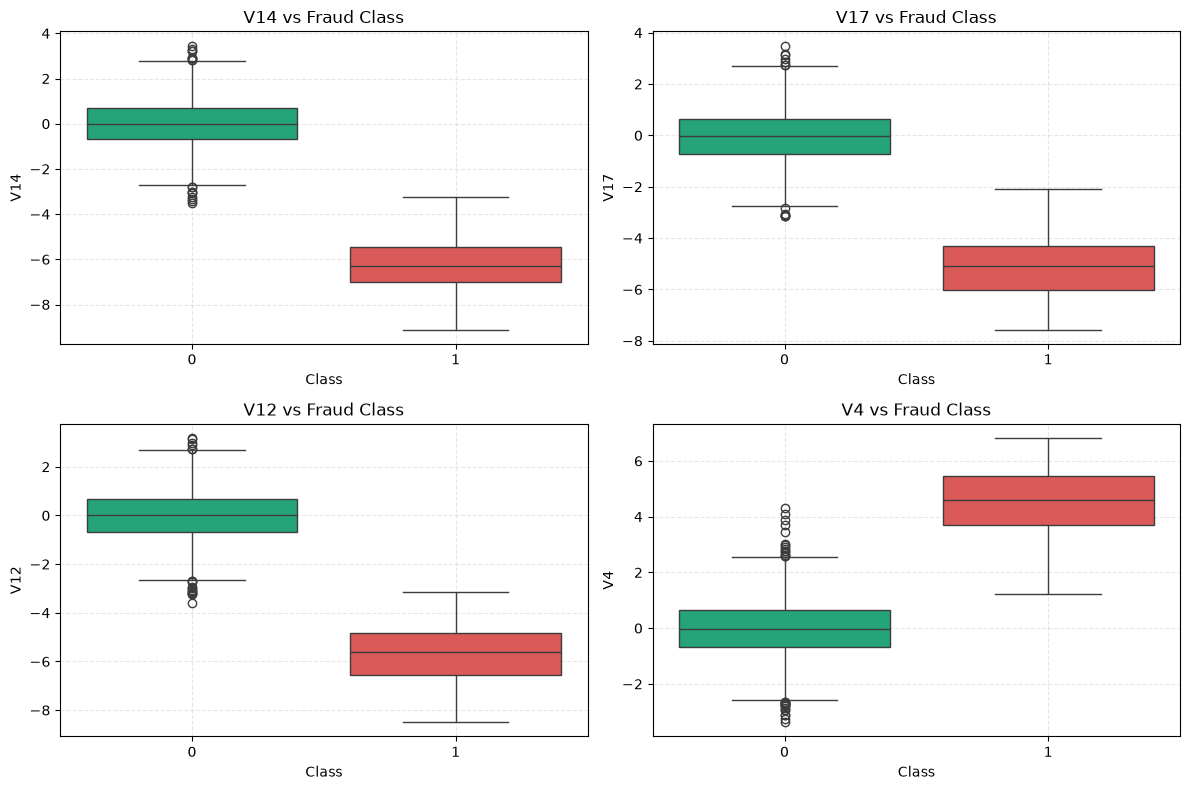

In [6]:
key_features = ["V14", "V17", "V12", "V4"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    sns.boxplot(x="Class", y=feat, data=df, ax=axes[i], palette=["#10b981", "#ef4444"])
    axes[i].set_title(f"{feat} vs Fraud Class")
    axes[i].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Correlation Heatmap
Verifying correlation among PCA transformed components and transaction class.

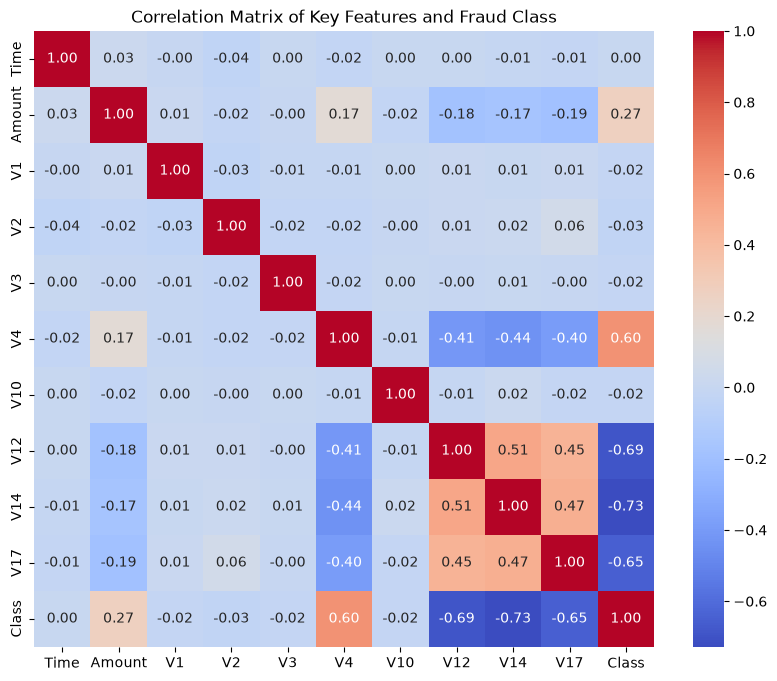

In [7]:
plt.figure(figsize=(10, 8))
sub_cols = ["Time", "Amount", "V1", "V2", "V3", "V4", "V10", "V12", "V14", "V17", "Class"]
corr = df[sub_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix of Key Features and Fraud Class")
plt.show()

## 7. Key Findings & Engineering Implications
1. **Severe Imbalance (~0.17% fraud in ULB):** Accuracy is strictly unusable; PR-AUC (Average Precision) and Sensitivity (Recall) must govern model selection.
2. **Outlier Skew in Amount:** RobustScaler is preferred over standard z-score scaling because median and interquartile range (IQR) resist outlier distortion.
3. **Chronological Splitting:** Random train/test shuffling leads to temporal data leakage in transaction streaming environments; chronological splits benchmark realistic production degradation.
4. **Discriminative Signatures:** Features V14, V17, and V12 strongly indicate fraud when their values plunge into negative territory, whereas V4 surges positively.